# Crime Category Classification — Final Complete Version

This notebook includes:
- Full data loading
- Data description
- Visualizations
- Preprocessing
- PCA/SVD
- Logistic Regression
- SVM
- Decision Tree
- CNN
- Accuracy comparison plots
- Confusion matrix
- Final submission file

In [1]:
import os, time, gc, warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler, OneHotEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.tree import DecisionTreeClassifier

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv1D, MaxPooling1D, Flatten, Dense, Dropout
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

print("Imports completed successfully")
print("TensorFlow:", tf.__version__)
print(os.listdir())

Imports completed successfully
TensorFlow: 2.21.0
['final_complete_crime_project_with_confusion_matrix.ipynb', 'test.csv', 'train.csv']


In [2]:
def find_file(names):
    for name in names:
        if os.path.exists(name):
            return name
    return None

train_path = find_file(["train.csv", "train", "Train.csv", "Train"])
test_path = find_file(["test.csv", "test", "Test.csv", "Test"])

if train_path is None:
    raise FileNotFoundError("Train file not found")
if test_path is None:
    raise FileNotFoundError("Test file not found")

start = time.time()
train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)

print("Train file:", train_path)
print("Test file:", test_path)
print("Loading time minutes:", round((time.time() - start) / 60, 2))
print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)

display(train_df.head())
display(test_df.head())

Train file: train.csv
Test file: test.csv
Loading time minutes: 0.02
Train shape: (878049, 9)
Test shape: (884262, 7)


,Dates,Category,Descript,DayOfWeek,PdDistrict,Resolution,Address,X,Y
0,2015-05-13 23:53:00,WARRANTS,WARRANT ARREST,Wednesday,NORTHERN,"ARREST, BOOKED",OAK ST / LAGUNA ST,-122.425892,37.774599
1,2015-05-13 23:53:00,OTHER OFFENSES,TRAFFIC VIOLATION ARREST,Wednesday,NORTHERN,"ARREST, BOOKED",OAK ST / LAGUNA ST,-122.425892,37.774599
2,2015-05-13 23:33:00,OTHER OFFENSES,TRAFFIC VIOLATION ARREST,Wednesday,NORTHERN,"ARREST, BOOKED",VANNESS AV / GREENWICH ST,-122.424363,37.800414
3,2015-05-13 23:30:00,LARCENY/THEFT,GRAND THEFT FROM LOCKED AUTO,Wednesday,NORTHERN,NONE,1500 Block of LOMBARD ST,-122.426995,37.800873
4,2015-05-13 23:30:00,LARCENY/THEFT,GRAND THEFT FROM LOCKED AUTO,Wednesday,PARK,NONE,100 Block of BRODERICK ST,-122.438738,37.771541


,Id,Dates,DayOfWeek,PdDistrict,Address,X,Y
0,0,2015-05-10 23:59:00,Sunday,BAYVIEW,2000 Block of THOMAS AV,-122.399588,37.735051
1,1,2015-05-10 23:51:00,Sunday,BAYVIEW,3RD ST / REVERE AV,-122.391523,37.732432
2,2,2015-05-10 23:50:00,Sunday,NORTHERN,2000 Block of GOUGH ST,-122.426002,37.792212
3,3,2015-05-10 23:45:00,Sunday,INGLESIDE,4700 Block of MISSION ST,-122.437394,37.721412
4,4,2015-05-10 23:45:00,Sunday,INGLESIDE,4700 Block of MISSION ST,-122.437394,37.721412


In [3]:
print("Columns:")
print(train_df.columns)

print("\nInfo:")
print(train_df.info())

print("\nMissing values:")
print(train_df.isnull().sum())

print("\nCategory distribution:")
print(train_df["Category"].value_counts())

print("\nNumber of categories:", train_df["Category"].nunique())

Columns:
Index(['Dates', 'Category', 'Descript', 'DayOfWeek', 'PdDistrict',
       'Resolution', 'Address', 'X', 'Y'],
      dtype='str')

Info:
<class 'pandas.DataFrame'>
RangeIndex: 878049 entries, 0 to 878048
Data columns (total 9 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   Dates       878049 non-null  str    
 1   Category    878049 non-null  str    
 2   Descript    878049 non-null  str    
 3   DayOfWeek   878049 non-null  str    
 4   PdDistrict  878049 non-null  str    
 5   Resolution  878049 non-null  str    
 6   Address     878049 non-null  str    
 7   X           878049 non-null  float64
 8   Y           878049 non-null  float64
dtypes: float64(2), str(7)
memory usage: 60.3 MB
None

Missing values:
Dates         0
Category      0
Descript      0
DayOfWeek     0
PdDistrict    0
Resolution    0
Address       0
X             0
Y             0
dtype: int64

Category distribution:
Category
LARCENY/THEFT                  17

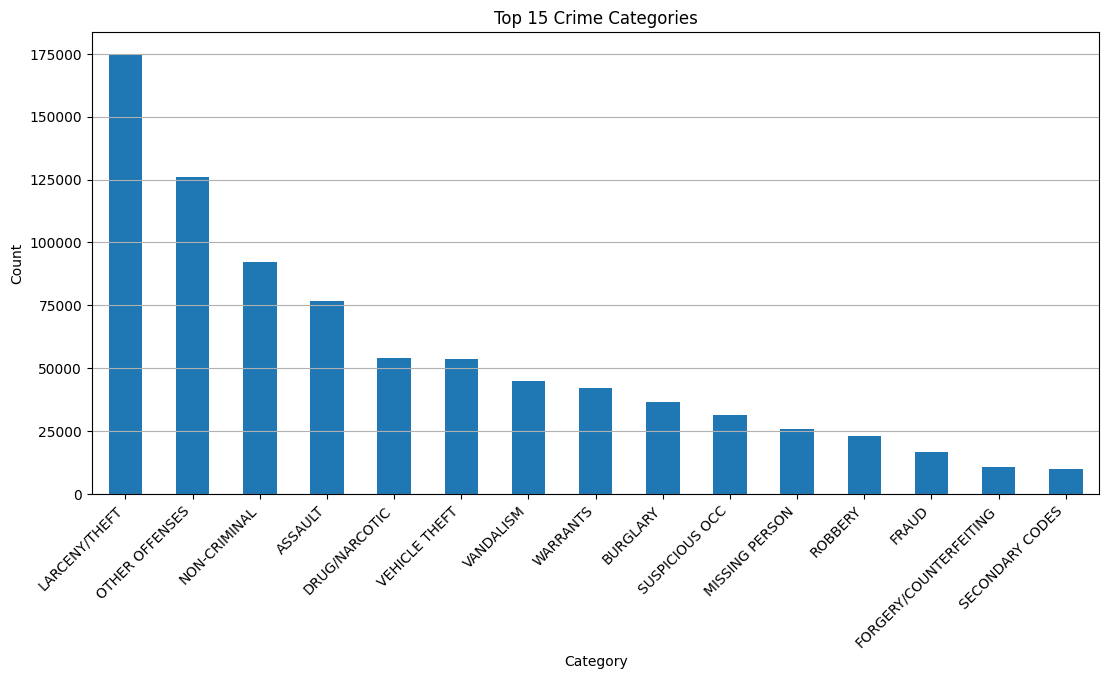

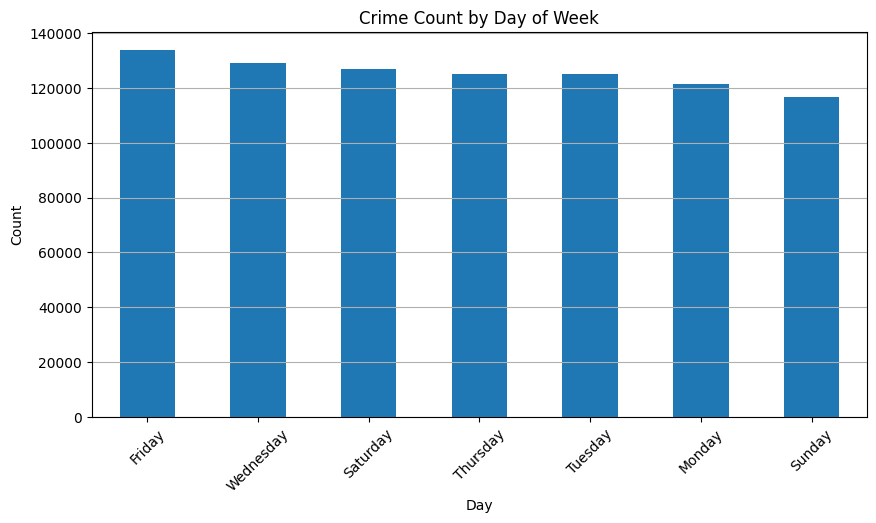

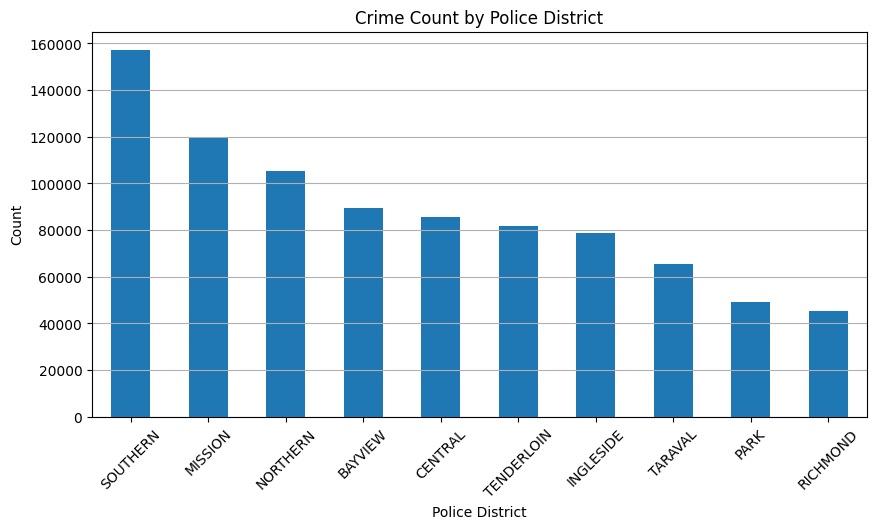

In [4]:
plt.figure(figsize=(13, 6))
train_df["Category"].value_counts().head(15).plot(kind="bar")
plt.title("Top 15 Crime Categories")
plt.xlabel("Category")
plt.ylabel("Count")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y")
plt.show()

plt.figure(figsize=(10, 5))
train_df["DayOfWeek"].value_counts().plot(kind="bar")
plt.title("Crime Count by Day of Week")
plt.xlabel("Day")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.grid(axis="y")
plt.show()

plt.figure(figsize=(10, 5))
train_df["PdDistrict"].value_counts().plot(kind="bar")
plt.title("Crime Count by Police District")
plt.xlabel("Police District")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.grid(axis="y")
plt.show()

In [5]:
def prepare_data(df):
    df = df.copy()
    df["Dates"] = pd.to_datetime(df["Dates"], errors="coerce")
    df["Year"] = df["Dates"].dt.year
    df["Month"] = df["Dates"].dt.month
    df["Day"] = df["Dates"].dt.day
    df["Hour"] = df["Dates"].dt.hour
    df["Minute"] = df["Dates"].dt.minute
    df["IsWeekend"] = df["DayOfWeek"].isin(["Saturday", "Sunday"]).astype(int)

    for col in ["DayOfWeek", "PdDistrict", "Address"]:
        df[col] = df[col].fillna("Unknown").astype(str)

    for col in ["X", "Y", "Year", "Month", "Day", "Hour", "Minute", "IsWeekend"]:
        df[col] = df[col].fillna(df[col].median())

    return df

start = time.time()
train_df = prepare_data(train_df)
test_df = prepare_data(test_df)

print("Feature engineering time minutes:", round((time.time() - start) / 60, 2))

Feature engineering time minutes: 0.02


In [6]:
target_col = "Category"

X = train_df.drop(columns=["Category", "Dates", "Descript", "Resolution"], errors="ignore")
y = train_df[target_col]

X_test_final = test_df.drop(columns=["Id", "Dates", "Descript", "Resolution"], errors="ignore")
test_ids = test_df["Id"] if "Id" in test_df.columns else np.arange(len(test_df))

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)
num_classes = len(label_encoder.classes_)

print("X shape:", X.shape)
print("X_test_final shape:", X_test_final.shape)
print("Number of classes:", num_classes)
print(label_encoder.classes_)

X shape: (878049, 11)
X_test_final shape: (884262, 11)
Number of classes: 39
['ARSON' 'ASSAULT' 'BAD CHECKS' 'BRIBERY' 'BURGLARY' 'DISORDERLY CONDUCT'
 'DRIVING UNDER THE INFLUENCE' 'DRUG/NARCOTIC' 'DRUNKENNESS'
 'EMBEZZLEMENT' 'EXTORTION' 'FAMILY OFFENSES' 'FORGERY/COUNTERFEITING'
 'FRAUD' 'GAMBLING' 'KIDNAPPING' 'LARCENY/THEFT' 'LIQUOR LAWS' 'LOITERING'
 'MISSING PERSON' 'NON-CRIMINAL' 'OTHER OFFENSES'
 'PORNOGRAPHY/OBSCENE MAT' 'PROSTITUTION' 'RECOVERED VEHICLE' 'ROBBERY'
 'RUNAWAY' 'SECONDARY CODES' 'SEX OFFENSES FORCIBLE'
 'SEX OFFENSES NON FORCIBLE' 'STOLEN PROPERTY' 'SUICIDE' 'SUSPICIOUS OCC'
 'TREA' 'TRESPASS' 'VANDALISM' 'VEHICLE THEFT' 'WARRANTS' 'WEAPON LAWS']


In [7]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

print("Training rows:", X_train.shape[0])
print("Validation rows:", X_valid.shape[0])

Training rows: 702439
Validation rows: 175610


In [8]:
cat_features = ["DayOfWeek", "PdDistrict"]
num_features = ["X", "Y", "Year", "Month", "Day", "Hour", "Minute", "IsWeekend"]

TFIDF_MAX_FEATURES = 7000
SVD_COMPONENTS = 250

preprocessor = ColumnTransformer(
    transformers=[
        ("address_tfidf", TfidfVectorizer(max_features=TFIDF_MAX_FEATURES, ngram_range=(1, 2)), "Address"),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features),
        ("num", StandardScaler(), num_features)
    ],
    remainder="drop"
)

svd = TruncatedSVD(n_components=SVD_COMPONENTS, random_state=42)
svd_scaler = StandardScaler()

print("TF-IDF max features:", TFIDF_MAX_FEATURES)
print("SVD components:", SVD_COMPONENTS)

TF-IDF max features: 7000
SVD components: 250


In [9]:
start = time.time()

X_train_prepared = preprocessor.fit_transform(X_train)
X_valid_prepared = preprocessor.transform(X_valid)
X_test_prepared = preprocessor.transform(X_test_final)

print("Prepared sparse shapes:")
print("X_train_prepared:", X_train_prepared.shape)
print("X_valid_prepared:", X_valid_prepared.shape)
print("X_test_prepared:", X_test_prepared.shape)

X_train_svd = svd.fit_transform(X_train_prepared)
X_valid_svd = svd.transform(X_valid_prepared)
X_test_svd = svd.transform(X_test_prepared)

X_train_svd = svd_scaler.fit_transform(X_train_svd).astype("float32")
X_valid_svd = svd_scaler.transform(X_valid_svd).astype("float32")
X_test_svd = svd_scaler.transform(X_test_svd).astype("float32")

del X_train_prepared, X_valid_prepared, X_test_prepared
gc.collect()

print("SVD shapes:")
print(X_train_svd.shape, X_valid_svd.shape, X_test_svd.shape)
print("Preprocessing + PCA/SVD time minutes:", round((time.time() - start) / 60, 2))

Prepared sparse shapes:
X_train_prepared: (702439, 7025)
X_valid_prepared: (175610, 7025)
X_test_prepared: (884262, 7025)
SVD shapes:
(702439, 250) (175610, 250) (884262, 250)
Preprocessing + PCA/SVD time minutes: 1.1


In [10]:
results = {}
trained_models = {}

def train_and_evaluate_sklearn(name, model, X_tr, y_tr, X_val, y_val):
    start = time.time()
    print("=" * 80)
    print("Training:", name)

    model.fit(X_tr, y_tr)

    train_pred = model.predict(X_tr)
    valid_pred = model.predict(X_val)

    train_acc = accuracy_score(y_tr, train_pred)
    valid_acc = accuracy_score(y_val, valid_pred)
    train_time = round((time.time() - start) / 60, 2)

    results[name] = {
        "Train Accuracy": train_acc,
        "Validation Accuracy": valid_acc,
        "Training Time Minutes": train_time
    }

    trained_models[name] = model

    print("Train Accuracy:", train_acc)
    print("Validation Accuracy:", valid_acc)
    print("Training Time Minutes:", train_time)
    print(classification_report(y_val, valid_pred, target_names=label_encoder.classes_))

    gc.collect()
    return model

In [11]:
logistic_model = LogisticRegression(
    max_iter=300,
    solver="saga",
    C=1.0,
    n_jobs=-1,
    verbose=1
)

logistic_model = train_and_evaluate_sklearn(
    "Logistic Regression + PCA/SVD",
    logistic_model,
    X_train_svd,
    y_train,
    X_valid_svd,
    y_valid
)

Training: Logistic Regression + PCA/SVD
convergence after 87 epochs took 1394 seconds
Train Accuracy: 0.2644642452938974
Validation Accuracy: 0.2641193553897842
Training Time Minutes: 23.24
                             precision    recall  f1-score   support

                      ARSON       0.00      0.00      0.00       303
                    ASSAULT       0.17      0.10      0.12     15375
                 BAD CHECKS       0.00      0.00      0.00        81
                    BRIBERY       0.00      0.00      0.00        58
                   BURGLARY       0.13      0.01      0.02      7351
         DISORDERLY CONDUCT       0.00      0.00      0.00       864
DRIVING UNDER THE INFLUENCE       0.00      0.00      0.00       454
              DRUG/NARCOTIC       0.29      0.37      0.32     10794
                DRUNKENNESS       0.00      0.00      0.00       856
               EMBEZZLEMENT       0.00      0.00      0.00       233
                  EXTORTION       0.00      0.00  

In [12]:
svm_model = SGDClassifier(
    loss="hinge",
    alpha=0.0001,
    max_iter=1000,
    tol=1e-3,
    random_state=42,
    n_jobs=-1
)

svm_model = train_and_evaluate_sklearn(
    "SVM SGDClassifier + PCA/SVD",
    svm_model,
    X_train_svd,
    y_train,
    X_valid_svd,
    y_valid
)

Training: SVM SGDClassifier + PCA/SVD
Train Accuracy: 0.1779926797914125
Validation Accuracy: 0.17730197596947783
Training Time Minutes: 3.94
                             precision    recall  f1-score   support

                      ARSON       0.00      0.00      0.00       303
                    ASSAULT       0.11      0.10      0.10     15375
                 BAD CHECKS       0.00      0.00      0.00        81
                    BRIBERY       0.00      0.00      0.00        58
                   BURGLARY       0.08      0.08      0.08      7351
         DISORDERLY CONDUCT       0.12      0.01      0.01       864
DRIVING UNDER THE INFLUENCE       0.00      0.00      0.00       454
              DRUG/NARCOTIC       0.20      0.24      0.22     10794
                DRUNKENNESS       0.00      0.00      0.00       856
               EMBEZZLEMENT       0.00      0.00      0.00       233
                  EXTORTION       0.00      0.00      0.00        51
            FAMILY OFFENSES  

In [13]:
decision_tree_model = DecisionTreeClassifier(
    max_depth=40,
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=42
)

decision_tree_model = train_and_evaluate_sklearn(
    "Decision Tree + PCA/SVD",
    decision_tree_model,
    X_train_svd,
    y_train,
    X_valid_svd,
    y_valid
)

Training: Decision Tree + PCA/SVD
Train Accuracy: 0.5081167190318305
Validation Accuracy: 0.2389271681567109
Training Time Minutes: 14.59
                             precision    recall  f1-score   support

                      ARSON       0.04      0.00      0.01       303
                    ASSAULT       0.16      0.23      0.19     15375
                 BAD CHECKS       0.00      0.00      0.00        81
                    BRIBERY       0.00      0.00      0.00        58
                   BURGLARY       0.11      0.12      0.12      7351
         DISORDERLY CONDUCT       0.05      0.02      0.03       864
DRIVING UNDER THE INFLUENCE       0.02      0.00      0.00       454
              DRUG/NARCOTIC       0.29      0.35      0.32     10794
                DRUNKENNESS       0.04      0.01      0.01       856
               EMBEZZLEMENT       0.04      0.00      0.01       233
                  EXTORTION       0.00      0.00      0.00        51
            FAMILY OFFENSES      

In [14]:
X_train_cnn = X_train_svd.reshape(X_train_svd.shape[0], X_train_svd.shape[1], 1)
X_valid_cnn = X_valid_svd.reshape(X_valid_svd.shape[0], X_valid_svd.shape[1], 1)
X_test_cnn = X_test_svd.reshape(X_test_svd.shape[0], X_test_svd.shape[1], 1)

y_train_cat = to_categorical(y_train, num_classes=num_classes)
y_valid_cat = to_categorical(y_valid, num_classes=num_classes)

print("CNN train shape:", X_train_cnn.shape)
print("CNN validation shape:", X_valid_cnn.shape)
print("CNN test shape:", X_test_cnn.shape)

CNN train shape: (702439, 250, 1)
CNN validation shape: (175610, 250, 1)
CNN test shape: (884262, 250, 1)


In [15]:
gc.collect()
start = time.time()

cnn_model = Sequential([
    Input(shape=(X_train_cnn.shape[1], 1)),
    Conv1D(32, kernel_size=3, activation="relu"),
    MaxPooling1D(pool_size=2),
    Dropout(0.25),

    Conv1D(64, kernel_size=3, activation="relu"),
    MaxPooling1D(pool_size=2),
    Dropout(0.25),

    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.4),
    Dense(num_classes, activation="softmax")
])

cnn_model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

cnn_model.summary()

callbacks = [
    EarlyStopping(monitor="loss", patience=3, restore_best_weights=True),
    ReduceLROnPlateau(monitor="loss", factor=0.5, patience=2, min_lr=1e-6)
]

history = cnn_model.fit(
    X_train_cnn,
    y_train_cat,
    epochs=15,
    batch_size=256,
    callbacks=callbacks,
    verbose=1
)

cnn_train_loss, cnn_train_acc = cnn_model.evaluate(X_train_cnn, y_train_cat, batch_size=256, verbose=0)
cnn_valid_loss, cnn_valid_acc = cnn_model.evaluate(X_valid_cnn, y_valid_cat, batch_size=256, verbose=0)

cnn_time = round((time.time() - start) / 60, 2)

results["CNN + PCA/SVD"] = {
    "Train Accuracy": cnn_train_acc,
    "Validation Accuracy": cnn_valid_acc,
    "Training Time Minutes": cnn_time
}

trained_models["CNN + PCA/SVD"] = cnn_model

print("CNN Train Accuracy:", cnn_train_acc)
print("CNN Validation Accuracy:", cnn_valid_acc)
print("CNN Training Time Minutes:", cnn_time)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 248, 32)        │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 124, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 124, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 122, 64)        │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 61, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 61, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3904)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       499,840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 39)             │         5,031 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 511,207 (1.95 MB)

 Trainable params: 511,207 (1.95 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
2744/2744 ━━━━━━━━━━━━━━━━━━━━ 42s 15ms/step - accuracy: 0.2461 - loss: 2.5377 - learning_rate: 0.0010
Epoch 2/15
2744/2744 ━━━━━━━━━━━━━━━━━━━━ 43s 16ms/step - accuracy: 0.2601 - loss: 2.4713 - learning_rate: 0.0010
Epoch 3/15
2744/2744 ━━━━━━━━━━━━━━━━━━━━ 41s 15ms/step - accuracy: 0.2637 - loss: 2.4525 - learning_rate: 0.0010
Epoch 4/15
2744/2744 ━━━━━━━━━━━━━━━━━━━━ 39s 14ms/step - accuracy: 0.2670 - loss: 2.4402 - learning_rate: 0.0010
Epoch 5/15
2744/2744 ━━━━━━━━━━━━━━━━━━━━ 40s 14ms/step - accuracy: 0.2679 - loss: 2.4329 - learning_rate: 0.0010
Epoch 6/15
2744/2744 ━━━━━━━━━━━━━━━━━━━━ 38s 14ms/step - accuracy: 0.2697 - loss: 2.4271 - learning_rate: 0.0010
Epoch 7/15
2744/2744 ━━━━━━━━━━━━━━━━━━━━ 39s 14ms/step - accuracy: 0.2705 - loss: 2.4232 - learning_rate: 0.0010
Epoch 8/15
2744/2744 ━━━━━━━━━━━━━━━━━━━━ 40s 14ms/step - accuracy: 0.2716 - loss: 2.4191 - learning_rate: 0.0010
Epoch 9/15
2744/2744 ━━━━━━━━━━━━━━━━━━━━ 40s 15ms/step - accuracy: 0.2721 - loss: 2.415

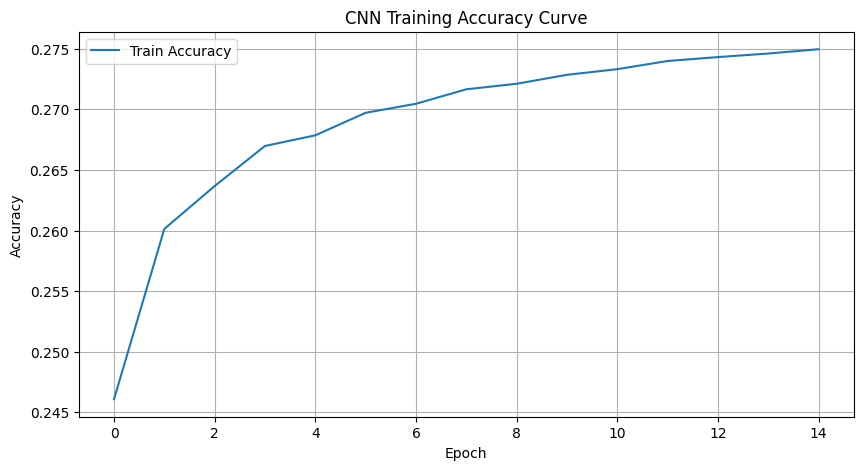

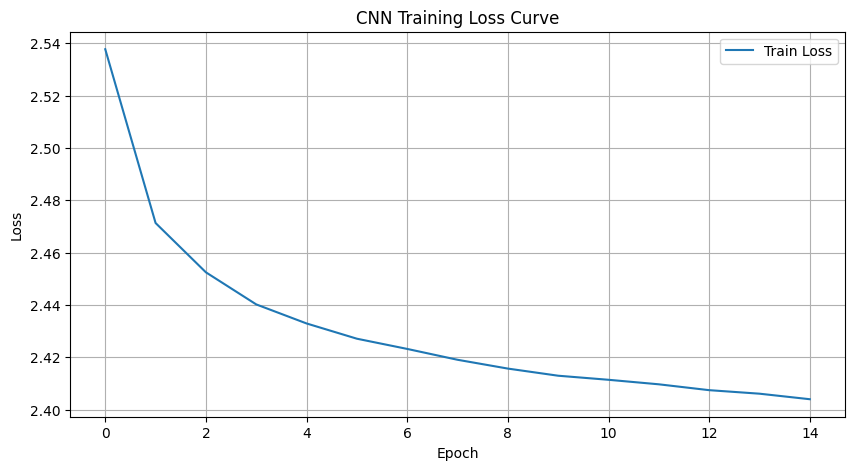

In [16]:
plt.figure(figsize=(10, 5))
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.title("CNN Training Accuracy Curve")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(history.history["loss"], label="Train Loss")
plt.title("CNN Training Loss Curve")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

In [17]:
results_df = pd.DataFrame(results).T
results_df = results_df.sort_values("Validation Accuracy", ascending=False)
display(results_df)

,Train Accuracy,Validation Accuracy,Training Time Minutes
CNN + PCA/SVD,0.290277,0.287239,10.32
Logistic Regression + PCA/SVD,0.264464,0.264119,23.24
Decision Tree + PCA/SVD,0.508117,0.238927,14.59
SVM SGDClassifier + PCA/SVD,0.177993,0.177302,3.94


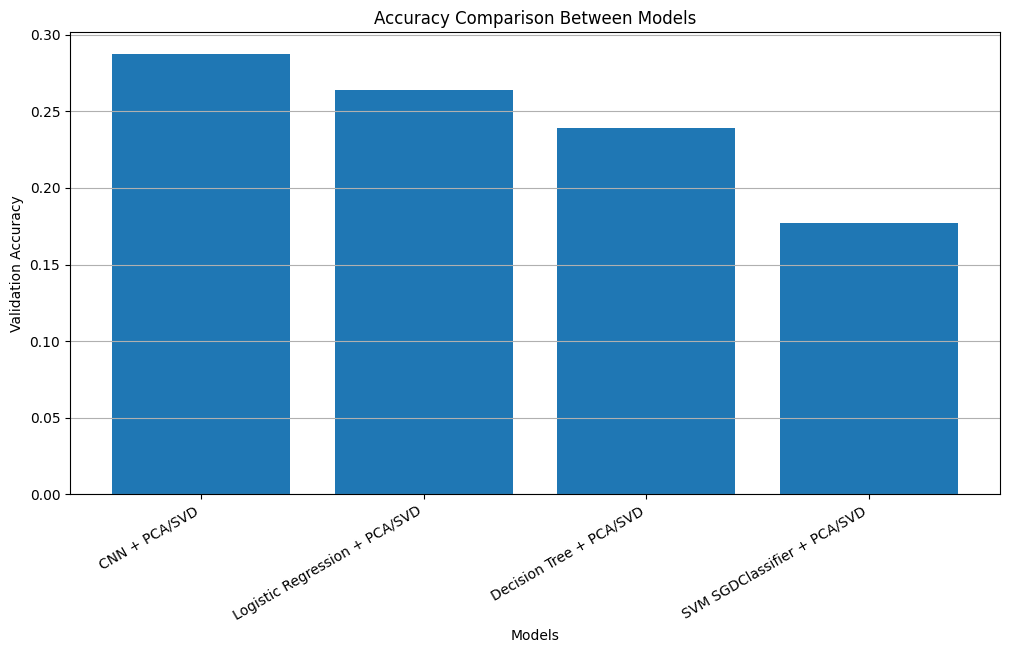

In [18]:
plt.figure(figsize=(12, 6))
plt.bar(results_df.index, results_df["Validation Accuracy"])
plt.title("Accuracy Comparison Between Models")
plt.xlabel("Models")
plt.ylabel("Validation Accuracy")
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y")
plt.show()

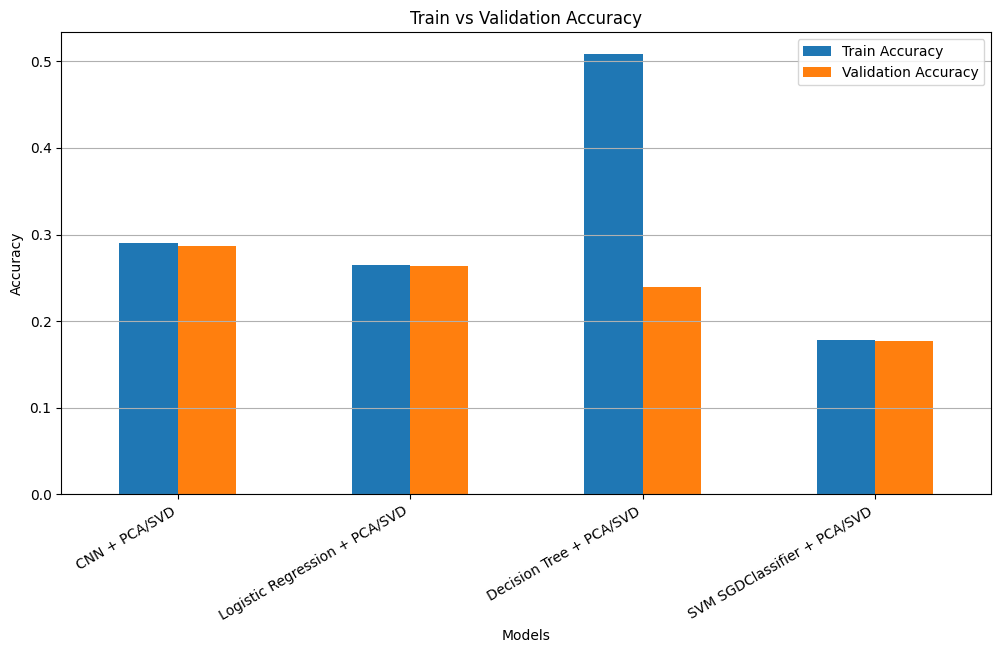

In [19]:
results_df[["Train Accuracy", "Validation Accuracy"]].plot(kind="bar", figsize=(12, 6))
plt.title("Train vs Validation Accuracy")
plt.xlabel("Models")
plt.ylabel("Accuracy")
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y")
plt.show()

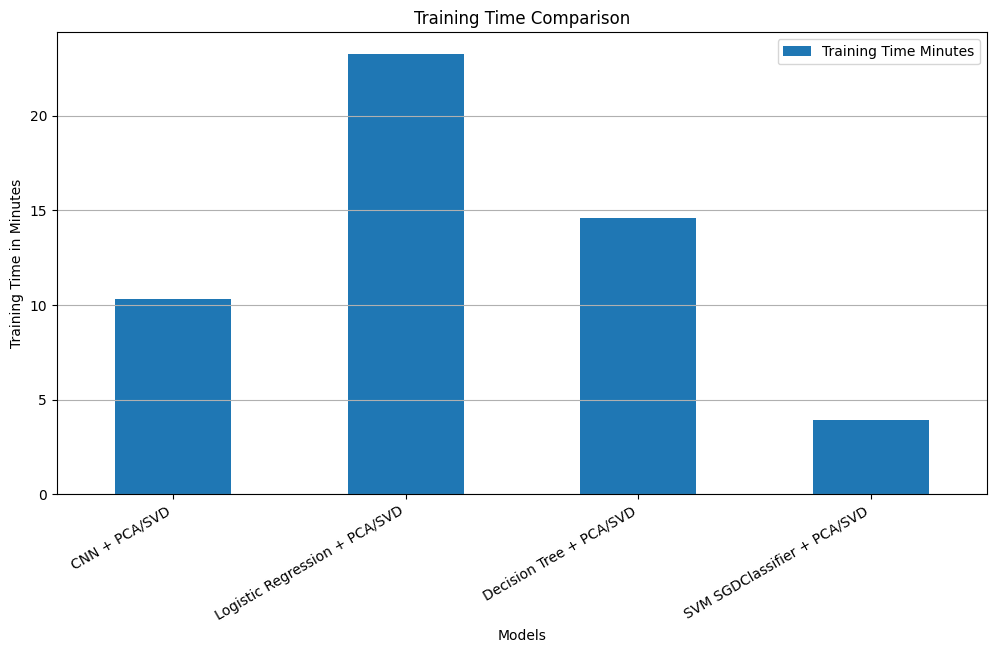

In [20]:
results_df[["Training Time Minutes"]].plot(kind="bar", figsize=(12, 6))
plt.title("Training Time Comparison")
plt.xlabel("Models")
plt.ylabel("Training Time in Minutes")
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y")
plt.show()

In [21]:
best_model_name = results_df.index[0]
best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)
print("Best Validation Accuracy:", results_df.iloc[0]["Validation Accuracy"])

Best Model: CNN + PCA/SVD
Best Validation Accuracy: 0.2872387766838074


686/686 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step


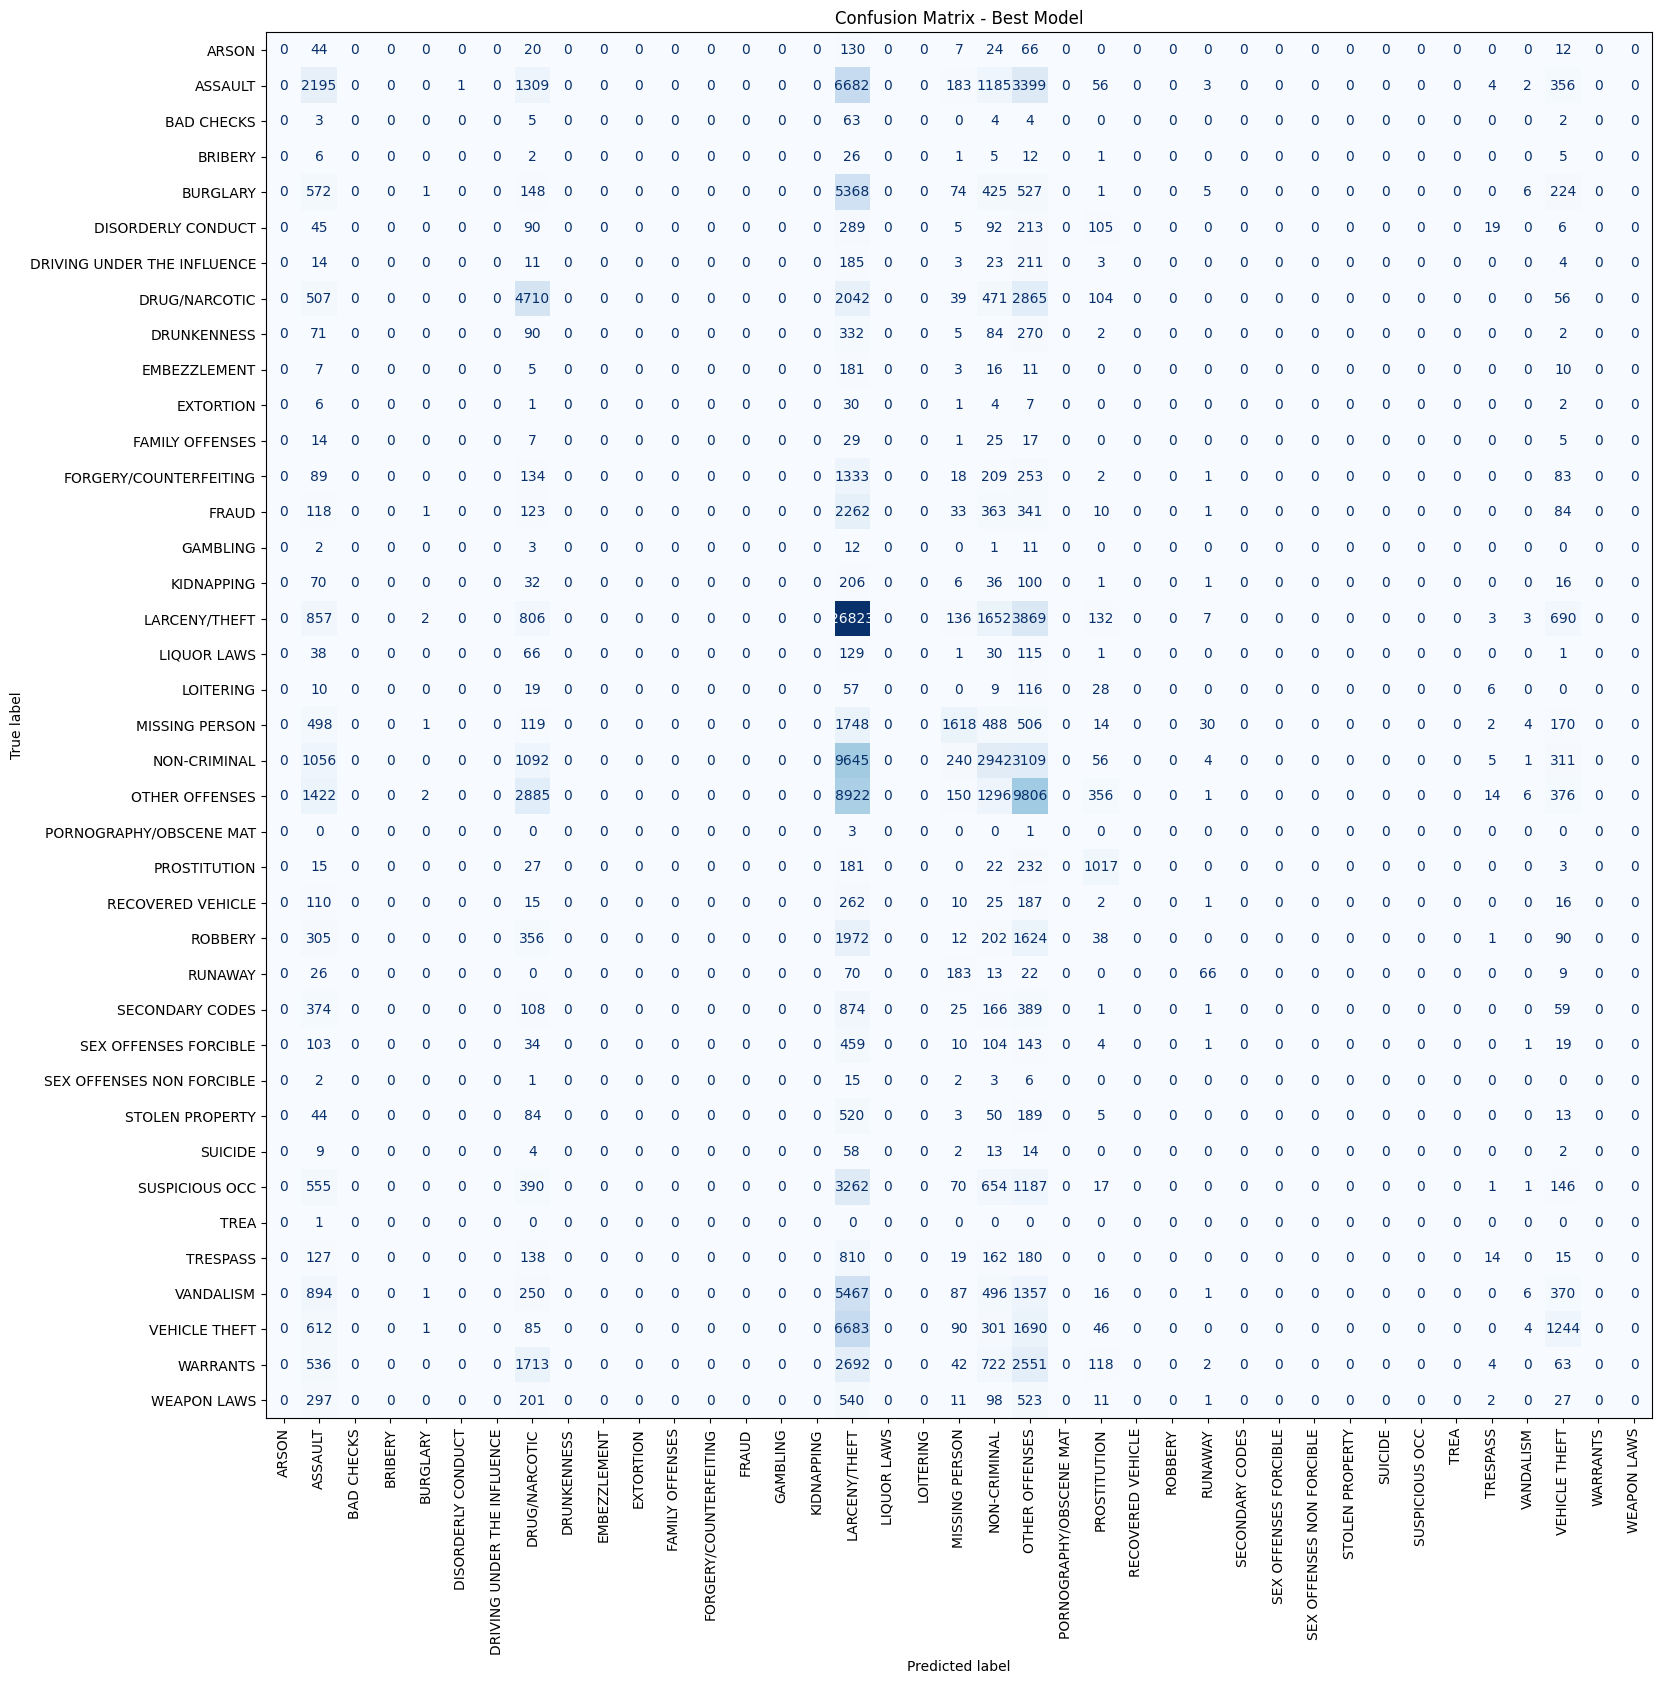

In [22]:
if best_model_name == "CNN + PCA/SVD":
    y_pred_proba = best_model.predict(X_valid_cnn, batch_size=256)
    y_pred = np.argmax(y_pred_proba, axis=1)
else:
    y_pred = best_model.predict(X_valid_svd)

cm = confusion_matrix(y_valid, y_pred)

fig, ax = plt.subplots(figsize=(18, 18))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_encoder.classes_)
disp.plot(ax=ax, xticks_rotation=90, cmap="Blues", values_format="d", colorbar=False)
plt.title("Confusion Matrix - Best Model")
plt.show()

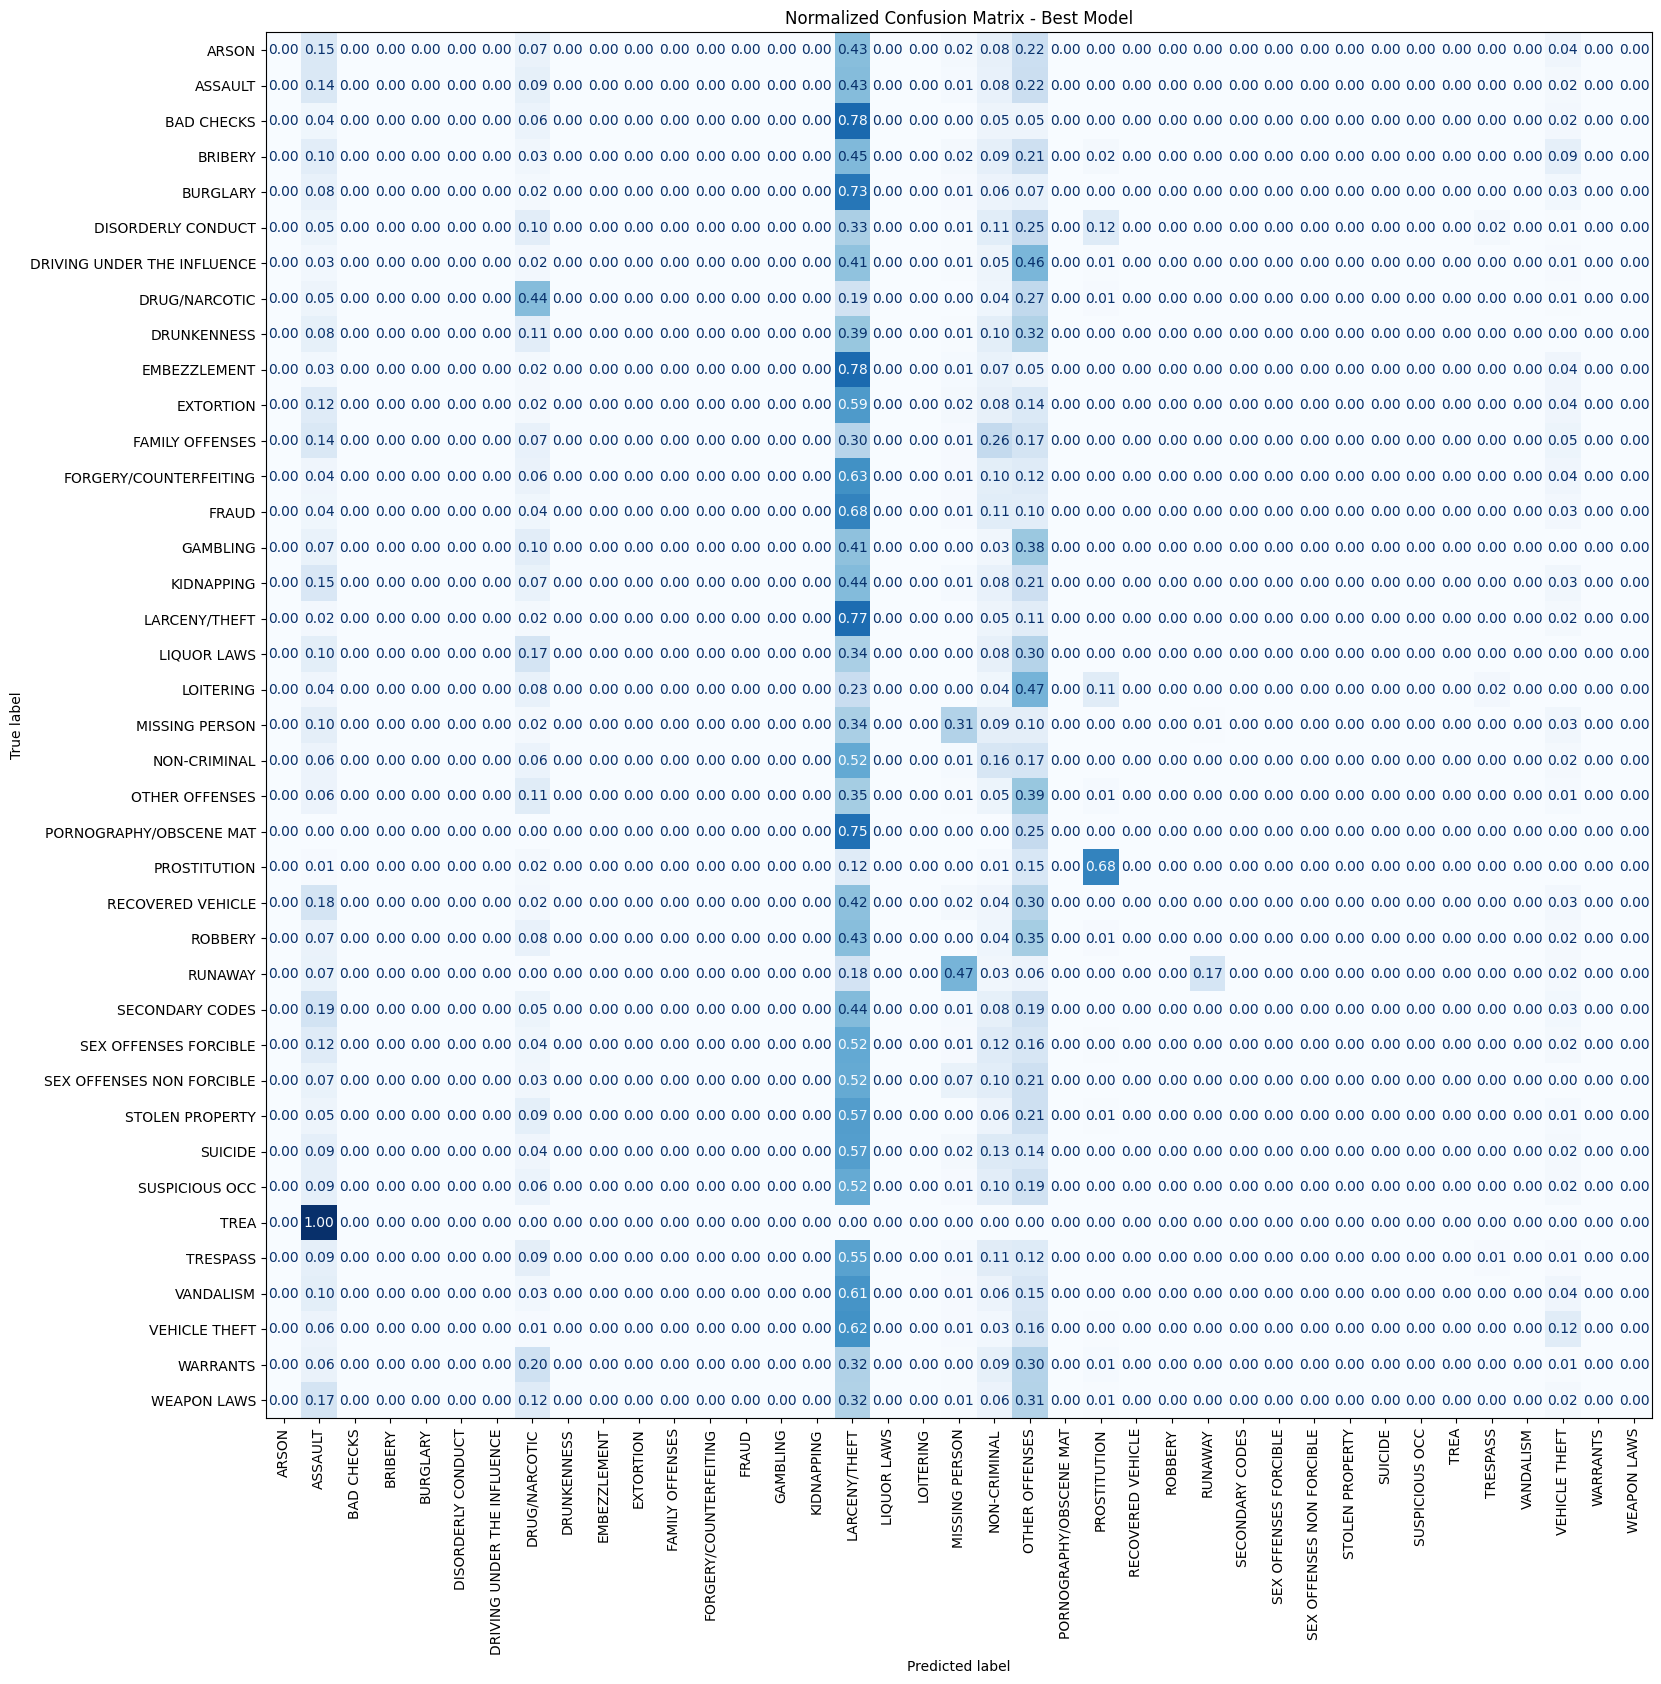

In [23]:
cm_normalized = confusion_matrix(y_valid, y_pred, normalize="true")

fig, ax = plt.subplots(figsize=(18, 18))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_normalized, display_labels=label_encoder.classes_)
disp.plot(ax=ax, xticks_rotation=90, cmap="Blues", values_format=".2f", colorbar=False)
plt.title("Normalized Confusion Matrix - Best Model")
plt.show()

In [24]:
joblib.dump(preprocessor, "preprocessor.pkl")
joblib.dump(svd, "svd.pkl")
joblib.dump(svd_scaler, "svd_scaler.pkl")
joblib.dump(label_encoder, "label_encoder.pkl")

if best_model_name == "CNN + PCA/SVD":
    best_model.save("final_best_model_cnn.keras")
    print("Saved best CNN model: final_best_model_cnn.keras")
else:
    joblib.dump(best_model, "final_best_model.pkl")
    print("Saved best sklearn model: final_best_model.pkl")

print("Preprocessing objects saved successfully.")

Saved best CNN model: final_best_model_cnn.keras
Preprocessing objects saved successfully.


In [25]:
if best_model_name == "CNN + PCA/SVD":
    test_pred_proba = best_model.predict(X_test_cnn, batch_size=256)
    test_pred_encoded = np.argmax(test_pred_proba, axis=1)
else:
    test_pred_encoded = best_model.predict(X_test_svd)

test_pred = label_encoder.inverse_transform(test_pred_encoded)

submission = pd.DataFrame({
    "Id": test_ids,
    "Category": test_pred
})

submission.to_csv("submission.csv", index=False)
display(submission.head())
print("submission.csv saved successfully.")

3455/3455 ━━━━━━━━━━━━━━━━━━━━ 13s 4ms/step


,Id,Category
0,0,OTHER OFFENSES
1,1,OTHER OFFENSES
2,2,LARCENY/THEFT
3,3,OTHER OFFENSES
4,4,OTHER OFFENSES


submission.csv saved successfully.


## Report Notes

- Full dataset was used without sampling.
- `Descript` and `Resolution` were removed to avoid data leakage.
- TF-IDF was applied to Address.
- OneHotEncoder was applied to categorical features.
- StandardScaler was applied to numerical features.
- TruncatedSVD was used as PCA-like dimensionality reduction.
- Logistic Regression, SVM, Decision Tree, and CNN were implemented.
- Accuracy comparison and confusion matrix were added.